# Credit card fraud (Kaggle Playground S6E11): summary

700k training transactions, 1.7% fraud. Metric: ROC AUC (how well fraud is ranked above non-fraud).
This notebook only reads saved results; every number is also in `EXPERIMENTS.md`.

1. Which columns carry signal
2. Which models work (shallow and additive beat deep)
3. Cross-validation vs the leaderboard
4. Where the final model still misses fraud

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
from src.fraud.config import OUTPUTS, RAW, ROOT, FOLD_SEEDS, EXTRA_FOLD_SEEDS
from src.fraud.metrics import auc
from src.fraud.features import strong_signals
from src.fraud.stack import feat, labels_and_zone, load, stack_oof
from experiments.round7_stack import SETS

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, GRAY = "#2a78d6", "#b9b8b1"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": SURFACE,
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": INK2, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9,
                     "axes.titlesize": 11, "axes.titlelocation": "left", "figure.dpi": 110,
                     "xtick.major.size": 0, "ytick.major.size": 0})
train = pd.read_csv(RAW / "train.csv")
y, zone, _ = labels_and_zone()
print(f"{len(train):,} rows, fraud rate {y.mean():.2%}")

699,960 rows, fraud rate 1.67%


## 1. Which columns carry signal

AUC of each numeric column used alone, in its stronger direction (0.5 = no signal; e.g. *fewer* hours since the last
transaction means more fraud). A few columns carry most of the signal; several (hour, day, card age, distance,
balance) are near 0.5 and were dropped as raw inputs.

True/False flags: fraud rate when True vs overall
                              share_true_%  fraud_rate_true_%   lift
col                                                                 
ip_country_mismatch                   1.62              16.50  11.56
is_ai_generated_scam_attempt          0.33              15.22   9.37
billing_shipping_mismatch             1.29              12.99   8.54
is_foreign_transaction                1.73              12.57   8.51
used_vpn                              3.38               6.55   4.37
is_new_merchant                      15.25               4.73   4.23


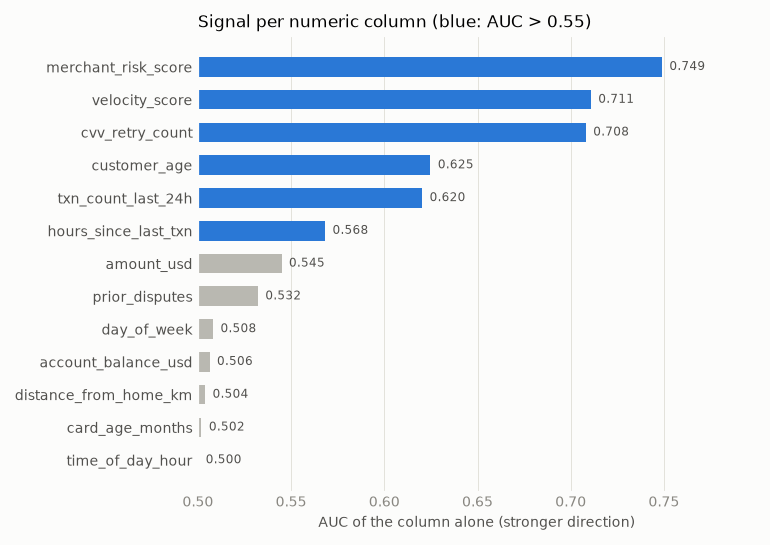

In [4]:
num = pd.read_csv(OUTPUTS / "eda" / "numeric.csv", index_col=0)
s = (0.5 + num["auc_strength"].abs()).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.32 * len(s) + 0.8))
ax.barh(s.index, s - 0.5, left=0.5, color=[BLUE if v > 0.55 else GRAY for v in s], height=0.6)
ax.axvline(0.5, color=MUTED, lw=1)
for i, v in enumerate(s):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=INK2)
ax.set_xlim(0.5, s.max() + 0.05); ax.set_xlabel("AUC of the column alone (stronger direction)")
ax.set_title("Signal per numeric column (blue: AUC > 0.55)"); ax.grid(axis="y", visible=False)
plt.tight_layout()
flags = pd.read_csv(OUTPUTS / "eda" / "booleans.csv", index_col=0)[["share_true_%", "fraud_rate_true_%", "lift"]]
print("True/False flags: fraud rate when True vs overall"); print(flags.round(2).to_string())

## 2. Which models work

Mean out-of-fold AUC over 3 CV splits (fold seeds 42 / 7 / 2026), same splits for every model, before the zone-1
rule and before averaging splits (the headline 0.9512 averages 7 splits and applies zone 1).
Target encoding (TE) of exact values was the first big step; after that, *simpler* models won: trees with 3 leaves
beat deeper trees, and an additive model (EBM) and a logistic regression on 42 "digit keys" were the best single
models. The final stack combines 8 of them with a logistic regression.

                           model     auc
                MLP (neural net) 0.94510
LightGBM 31 leaves, raw features 0.94576
         LightGBM 31 leaves + TE 0.94719
                 XGBoost depth 6 0.94813
                CatBoost depth 6 0.94816
              LightGBM 15 leaves 0.94823
               LightGBM 7 leaves 0.94870
                 XGBoost depth 2 0.94906
               LightGBM 3 leaves 0.94915
            EBM (additive model) 0.94958
     LightGBM 3 leaves + 42 keys 0.95019
   Logistic regression + 42 keys 0.95031
       Stack of 8 models (final) 0.95077


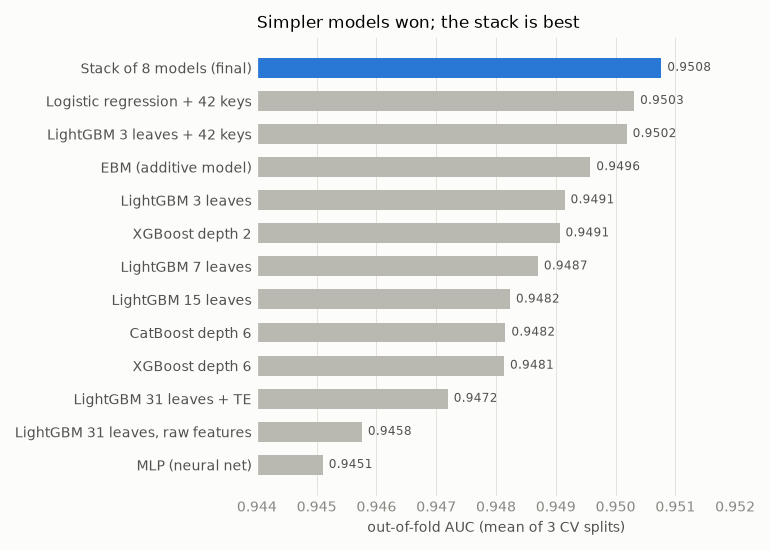

In [6]:
MODELS = [("LightGBM 31 leaves, raw features", "confirm_ei", "raw"),
          ("LightGBM 31 leaves + TE", "confirm_ei", "ei"),
          ("XGBoost depth 6", "models_v2", "xgb"), ("CatBoost depth 6", "models_v2", "catboost"),
          ("LightGBM 15 leaves", "models_v2", "lgb_l15"), ("LightGBM 7 leaves", "models_v2", "lgb_shallow"),
          ("MLP (neural net)", "nn_mlp", "mlp"), ("XGBoost depth 2", "models_v2", "xgb_d2"),
          ("LightGBM 3 leaves", "models_v2", "lgb_l3"), ("EBM (additive model)", "round4", "ebm"),
          ("LightGBM 3 leaves + 42 keys", "round7", "lgb_l3_k42_x3"),
          ("Logistic regression + 42 keys", "round7", "glm_plain")]
rows = [(name, np.mean([auc(y, np.load(OUTPUTS / d / f"oof_{m}_{s}.npy")) for s in FOLD_SEEDS]))
        for name, d, m in MODELS]
members = SETS["v4_x3"]
stack = [auc(y, stack_oof(np.column_stack([feat(m, load("oof", m, s)) for m in members]), y, s))
         for s in FOLD_SEEDS]
rows.append(("Stack of 8 models (final)", np.mean(stack)))
res = pd.DataFrame(rows, columns=["model", "auc"]).sort_values("auc")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(res.model, res.auc - 0.944, left=0.944, height=0.6,
        color=[BLUE if "final" in m else GRAY for m in res.model])
for i, v in enumerate(res.auc):
    ax.text(v + 0.0001, i, f"{v:.4f}", va="center", fontsize=8, color=INK2)
ax.set_xlim(0.944, 0.9520); ax.set_xlabel("out-of-fold AUC (mean of 3 CV splits)")
ax.set_title("Simpler models won; the stack is best"); ax.grid(axis="y", visible=False)
plt.tight_layout()
print(res.round(5).to_string(index=False))

## 3. Cross-validation vs the leaderboard

Each submission's public leaderboard score was within 0.0012 of its cross-validation score, so choices were
made on CV only (the public board is 20% of the test set and easy to over-fit).

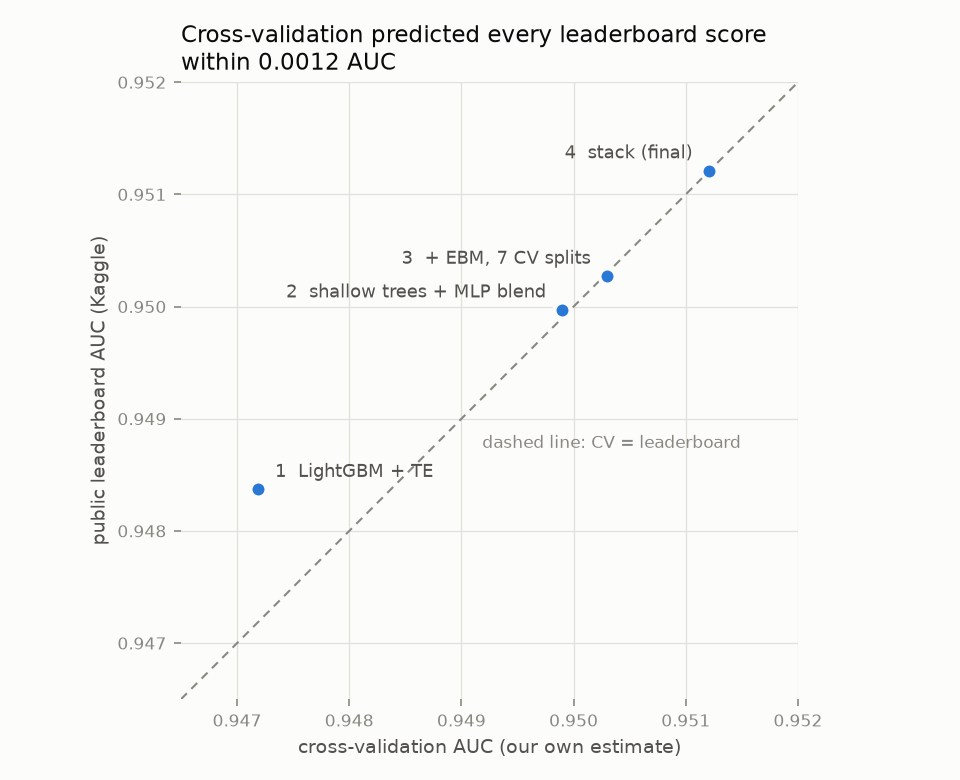

In [8]:
from IPython.display import Image
Image(filename=str(ROOT / "figures" / "cv_vs_lb.png"), width=480)

## 4. Where the final model still misses fraud

Rows grouped by how many strong fraud signals they show (CVV retries, no authentication, mismatch flags, ...).
Share of each group's frauds that the final stack ranks in its top 5% of scores (7 CV splits averaged).
Frauds with obvious signals are caught; frauds with no signal look like normal transactions and are mostly missed.
This overlap is the likely ceiling for every model here.

final stack OOF AUC (7 splits, zone 1): 0.95121
                   frauds  share_of_frauds  caught_in_top_5%
0\n10% of frauds     1185            0.101             0.121
1\n30% of frauds     3547            0.303             0.517
2\n34% of frauds     3926            0.336             0.905
3+\n26% of frauds    3031            0.259             0.994


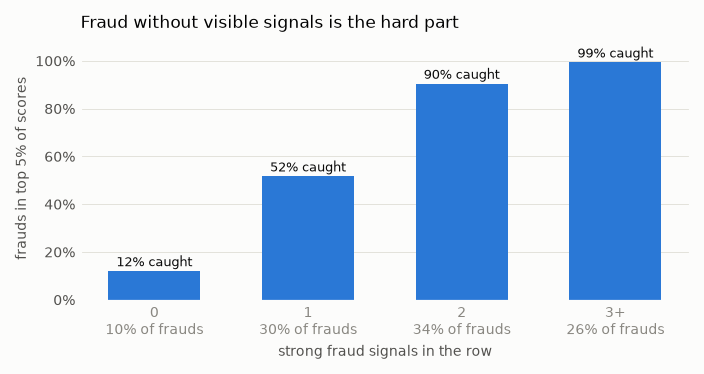

In [10]:
seeds = FOLD_SEEDS + EXTRA_FOLD_SEEDS
score = np.mean([rankdata(stack_oof(np.column_stack([feat(m, load("oof", m, s)) for m in members]), y, s))
                 for s in seeds], axis=0)
score = np.where(zone, score - 1e9, score)
top = score >= np.quantile(score, 0.95)
sig = np.minimum(strong_signals(train), 3)
g = pd.DataFrame({"signals": sig, "fraud": y, "top": top}).query("fraud == 1").groupby("signals")
tab = pd.DataFrame({"frauds": g.size(), "share_of_frauds": g.size() / y.sum(), "caught_in_top_5%": g["top"].mean()})
tab.index = [f"{k}\n{sh:.0%} of frauds" for k, sh in zip(["0", "1", "2", "3+"], tab["share_of_frauds"])]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(tab.index, tab["caught_in_top_5%"], color=BLUE, width=0.6)
for i, c in enumerate(tab["caught_in_top_5%"]):
    ax.text(i, c + 0.02, f"{c:.0%} caught", ha="center", fontsize=8.5, color=INK)
ax.set_ylim(0, 1.1); ax.set_xlabel("strong fraud signals in the row")
ax.set_ylabel("frauds in top 5% of scores"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Fraud without visible signals is the hard part"); ax.grid(axis="x", visible=False)
plt.tight_layout()
print(f"final stack OOF AUC (7 splits, zone 1): {auc(y, score):.5f}")
print(tab.round(3).to_string())

## 5. What the missed frauds look like, and why they are missed

"Missed" = a fraud the final stack scores below its 80th percentile; "caught" = a fraud in its top 5%.

**5a. Missed frauds look like ordinary transactions.** Medians (and the most common category) per group: missed
frauds sit a little above normal on every signal but close to legit rows, far from the frauds that are caught.

In [12]:
pct = rankdata(score) / len(score)
groups = {"missed fraud": (y == 1) & (pct < 0.80), "caught fraud": (y == 1) & (pct >= 0.95), "legit": y == 0}
cols = ["merchant_risk_score", "velocity_score", "customer_age", "cvv_retry_count", "txn_count_last_24h"]
prof = pd.DataFrame({g: train.loc[m, cols].median().round(1).astype(str) for g, m in groups.items()})
prof.loc["strong signals (mean)"] = [f"{sig[m].mean():.2f}" for m in groups.values()]
for c in ["auth_method", "merchant_category"]:
    top1 = [train.loc[m, c].value_counts(normalize=True).head(1) for m in groups.values()]
    prof.loc[f"most common {c}"] = [f"{t.index[0]} ({t.iloc[0]:.0%})" for t in top1]
prof.loc["rows"] = [f"{int(m.sum()):,}" for m in groups.values()]
miss = groups["missed fraud"]
for m in members:  # does any single model rank the missed frauds high?
    r = np.mean([rankdata(load("oof", m, s)) for s in seeds], axis=0) / len(y)
    print(f"{m:16s} puts {(r[miss] >= 0.95).mean():.1%} of the missed frauds in its own top 5%")
prof

ebm              puts 0.0% of the missed frauds in its own top 5%
lgb_l3_b1023_x3  puts 0.0% of the missed frauds in its own top 5%
xgb_d2_x3        puts 0.0% of the missed frauds in its own top 5%
mlp              puts 0.0% of the missed frauds in its own top 5%
mlp_d            puts 0.0% of the missed frauds in its own top 5%
glm_plain        puts 0.0% of the missed frauds in its own top 5%
lgb_l3_k42_x3    puts 0.0% of the missed frauds in its own top 5%
cat_d2_k42       puts 0.0% of the missed frauds in its own top 5%


,missed fraud,caught fraud,legit
merchant_risk_score,36.4,47.4,34.0
velocity_score,21.0,27.9,18.5
customer_age,56.0,63.0,52.0
cvv_retry_count,0.0,1.0,0.0
txn_count_last_24h,3.0,4.0,3.0
strong signals (mean),0.40,2.10,0.39
most common auth_method,3D Secure (34%),No Authentication (44%),3D Secure (30%)
most common merchant_category,Online Retail (24%),Electronics (14%),Online Retail (22%)
rows,878,"8,544","688,271"


**5b. Catching them would cost hundreds of false alarms each.** Fraud rate per band of the final score.
About 85% of the missed frauds sit in the 50-80 bands (blue), where only 0.2-0.6% of rows are fraud: to flag them, the model would also
flag roughly 170-480 legitimate transactions per extra fraud caught. In the top 1%, two of three flagged rows are
fraud.

missed frauds per band:
0-50      127
50-60     145
60-70     202
70-80     404
80-90       0
90-95       0
95-99       0
99-100      0


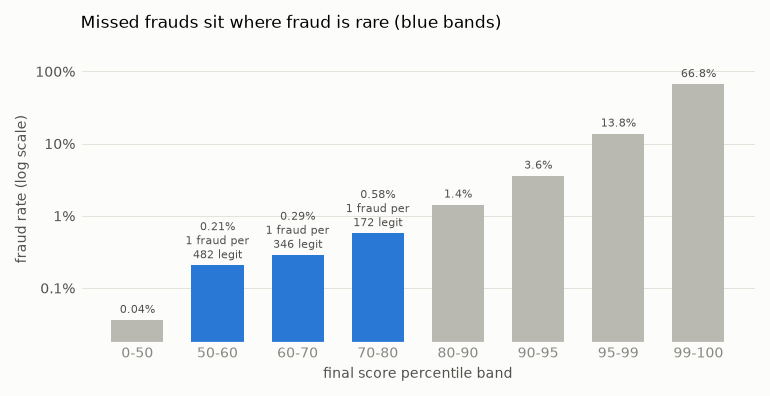

In [14]:
edges = [0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0001]
labels = ["0-50", "50-60", "60-70", "70-80", "80-90", "90-95", "95-99", "99-100"]
band = pd.cut(pct, edges, labels=labels, right=False)
rate = pd.Series(y).groupby(band, observed=False).mean()
fig, ax = plt.subplots(figsize=(7, 3.6))
mid = [l in ("50-60", "60-70", "70-80") for l in labels]
ax.bar(labels, rate, color=[BLUE if m else GRAY for m in mid], width=0.65)
ax.set_yscale("log"); ax.minorticks_off()
for i, r in enumerate(rate):
    note = (f"{r:.2%}" if r < 0.01 else f"{r:.1%}") + (f"\n1 fraud per\n{(1 - r) / r:.0f} legit" if mid[i] else "")
    ax.text(i, r * 1.25, note, ha="center", fontsize=7.5, color=INK2)
ax.set_ylim(rate.min() / 2, 3); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1%}" if v < 0.01 else f"{v:.0%}")
ax.set_xlabel("final score percentile band"); ax.set_ylabel("fraud rate (log scale)")
ax.set_title("Missed frauds sit where fraud is rare (blue bands)"); ax.grid(axis="x", visible=False)
plt.tight_layout()
print("missed frauds per band:"); print(pd.Series(band[groups["missed fraud"]]).value_counts().reindex(labels).to_string())

**5c. Why the model scores them low: three examples.** The EBM member is additive, so each row's score splits
into one contribution per column. It was fit on one fold's training rows and explains rows it never saw
(`eda/explain_missed.py`). Every row starts from a baseline of about -6.6 (log-odds, i.e. ~0.1%). The caught fraud
gets three or four large pushes (mismatch flags, CVV retries). The missed frauds only get small pushes from
slightly high merchant risk, velocity or age, not enough to stand out from thousands of similar legitimate rows.

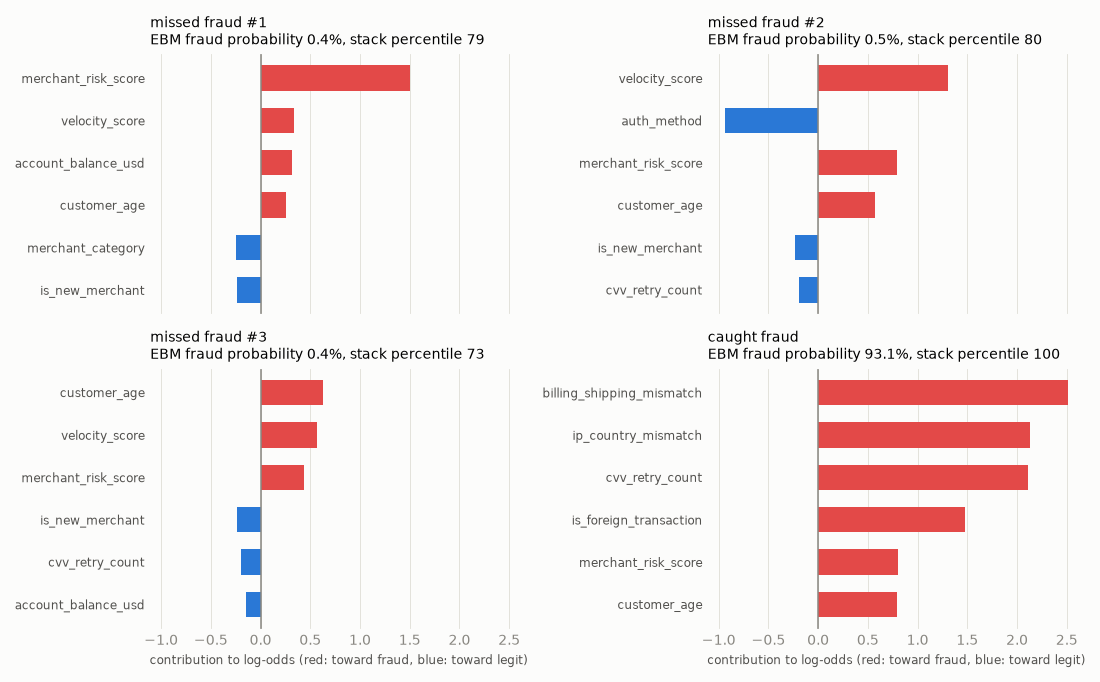

,merchant_category,auth_method,channel,merchant_risk_score,velocity_score,cvv_retry_count,customer_age,amount_usd
example,,,,,,,,
missed fraud #1,Electronics,OTP,Online,55.3,23.0,0,54,831.27
missed fraud #2,Online Retail,Biometric,POS,43.2,34.2,0,72,48.08
missed fraud #3,Restaurants,3D Secure,POS,38.0,30.5,0,81,44.46
caught fraud,Fuel,OTP,Online,50.1,10.1,1,65,48.57


In [16]:
ex = pd.read_csv(OUTPUTS / "notebook" / "ebm_examples.csv")
rows = pd.read_csv(OUTPUTS / "notebook" / "ebm_example_rows.csv").set_index("example")
RED = "#e34948"
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2), sharex=True)
for ax, (name, g) in zip(axes.ravel(), ex.groupby("example", sort=False)):
    g = g[g.column != "(intercept)"]
    top = g.reindex(g.contribution.abs().sort_values(ascending=False).index).head(6)[::-1]
    ax.barh(top.column, top.contribution, color=[RED if v > 0 else BLUE for v in top.contribution], height=0.6)
    ax.axvline(0, color=MUTED, lw=1)
    r = rows.loc[name]
    ax.set_title(f"{name}\nEBM fraud probability {r.ebm_probability:.1%}, stack percentile "
                 f"{r.stack_score_percentile:.0f}", fontsize=9)
    ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
for ax in axes[1]:
    ax.set_xlabel("contribution to log-odds (red: toward fraud, blue: toward legit)", fontsize=8)
plt.tight_layout()
rows[["merchant_category", "auth_method", "channel", "merchant_risk_score", "velocity_score", "cvv_retry_count",
      "customer_age", "amount_usd"]]

**5d. What this means.** The missed frauds are not a modelling failure that a better algorithm would fix: none
of the 8 models in the stack puts any of them in its top 5%, and they share their profile with hundreds of
legitimate rows. Catching them would need information this dataset does not have, such as the customer's own
spending history, the device used, or the merchant's past fraud reports. Within the competition, this overlap is
the likely ceiling for every model.